# 01. 모델 비교 → 최종 모델 선정
**해파리 급증 예측**: 권역별 이번 주 출현율과 바다 날씨로 1·2·4주 뒤 급증(통합 출현율 50% 미만 → 50% 이상)을 예측

| 단계 | 내용 |
|---|---|
| 입력 변수 | 제안서 3.6절 11개 (수온_변화_1주만 코드에서 생성) |
| 분할 | 시작일 순서로 train 70% / valid 10% / test 20% |
| 결측 | 정답(y)이 빈 행은 제외, 입력 결측 대체·표준화 기준은 train으로만 계산 (데이터 오류값은 DB 전처리에서 결측 처리됨) |
| 비교 모델 | 기준선(통합만) / 로지스틱 회귀 / LightGBM / XGBoost |
| 선정 | 하이퍼파라미터·최종 모델은 valid PR-AUC, test는 마지막에 한 번만 평가 |
| 최종 모델 규칙 | 1·2·4주 뒤 중 valid PR-AUC 1위를 가장 많이 한 모델 (동률이면 평균) |

**사용법**: 설정 셀의 `DATA_PATH`만 최종 파일로 바꾸고 위에서부터 차례로 실행

## 1. 라이브러리

In [1]:
import itertools
import os
import warnings

import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## 2. 설정

In [2]:
# ============================== [설정] ==============================
DATA_PATH = "학습데이터.csv"      # 최종 학습데이터 파일 (.csv 또는 .xlsx, 열 이름은 v_학습데이터 뷰와 같아야 함)
SHEET_NAME = 0                    # .xlsx일 때 읽을 시트 이름 또는 번호
OUT_DIR = "결과"

# 입력 변수 11개 (제안서 3.6절). 수온_변화_1주만 코드에서 만들고 나머지는 파일의 열 그대로 사용
FEATURES = [
    "통합", "통합_1주전", "통합_2주전", "통합_변화_1주",   # 현재·1~2주 전 출현율과 변화량
    "연중주차",                                          # 계절
    "수온_주평균", "수온_평년차", "수온_변화_1주",          # 수온·수온 평년차·수온 변화량
    "기온_주평균", "풍속_주평균", "유의파고_주평균",         # 기온·풍속·파고
]
BASELINE_FEATURES = ["통합"]      # 기준선: 현재 출현율만 사용 (비교용)

HORIZONS = [1, 2, 4]              # 1·2·4주 뒤 예측
TARGET = "타깃_급증_{k}주후"        # 정답 열 이름 형식
DATE_COL = "시작일"                # 시간 순서 분할 기준 열
SPLIT_RATIO = (0.7, 0.1, 0.2)     # train : valid : test
EXCLUDE_SPLIT = ["추가(2024)"]     # '분할' 열에서 이 값인 행은 제외 (2024년 5월 보고 종료로 생긴 짧은 구간)
THRESH = 0.5                      # 재현율·정밀도 계산용 확률 임계값
SEED = 42

# 데이터 오류는 DB 전처리(전처리_보정.py)에서만 고치고, 여기서는 고쳐졌는지 확인만 한다
#   포항 부이(22106) 2018-12-06~16 수온 센서 고장 → DB에서 해당 주 수온 NULL
#   → 이 기간 주평균을 쓰는 경북 2018-11-30, 2018-12-07 보고의 수온이 비어 있어야 함
SENSOR_CHECK = [{"관측소ID": 22106, "시작일": ["2018-11-30", "2018-12-07"]}]
TEMP_COLS = ["수온_주평균", "수온_평년차"]
os.makedirs(OUT_DIR, exist_ok=True)
FINAL_MODEL = "Logistic"          # 최종 모델. None으로 두면 규칙(valid 1위 횟수 최다)으로 자동 선정

## 3. 함수: 데이터 읽기·전처리·분할·모델 정의
- `load_data`: 파일 읽기, 필요한 열 확인, '추가(2024)' 20행 제외, DB에서 센서 고장값이 결측 처리됐는지 확인
- `add_features`: 수온_변화_1주 생성 (같은 권역 4~10일 전 보고와의 수온 차이)
- `time_split`: 날짜 순서로 7:1:2 분할
- 모델: 로지스틱(중앙값 대체 + 표준화 + class_weight), LightGBM·XGBoost(결측 그대로 입력, 클래스 가중치)

In [3]:
def load_data(path=DATA_PATH):
    """파일을 읽고 필요한 열을 확인한 뒤, '추가(2024)' 행을 빼고 권역·날짜 순으로 정렬한다."""
    if path.lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=SHEET_NAME)
    else:
        try:
            df = pd.read_csv(path, encoding="utf-8-sig")
        except UnicodeDecodeError:
            df = pd.read_csv(path, encoding="cp949")
    df.columns = df.columns.str.strip()

    base_cols = [c for c in FEATURES if c != "수온_변화_1주"]
    need = ["권역명", DATE_COL] + base_cols + [TARGET.format(k=k) for k in HORIZONS]
    missing = [c for c in need if c not in df.columns]
    if missing:
        raise ValueError(f"파일에 다음 열이 없습니다: {missing}")

    if "분할" in df.columns and EXCLUDE_SPLIT:
        df = df[~df["분할"].isin(EXCLUDE_SPLIT)]
    df[DATE_COL] = pd.to_datetime(df[DATE_COL])
    df = df.sort_values(["권역명", DATE_COL]).reset_index(drop=True)
    check_sensor_errors(df)
    return df


def check_sensor_errors(df):
    """DB에서 센서 고장값이 결측 처리됐는지 확인만 한다 (값은 바꾸지 않음)."""
    for e in SENSOR_CHECK:
        m = (df["관측소ID"] == e["관측소ID"]) & df[DATE_COL].isin(pd.to_datetime(e["시작일"]))
        left = df.loc[m, TEMP_COLS].notna().any(axis=1).sum()
        if left:
            print(f"⚠️ 경고: 관측소 {e['관측소ID']} 센서 고장 구간 수온이 {left}행 남아 있음 → DB 전처리(전처리_보정.py) 확인 필요")
        else:
            print(f"확인: 관측소 {e['관측소ID']} 센서 고장 구간 수온 결측 처리됨 ({m.sum()}행)")


def add_features(df):
    """제안서의 '수온 변화량' = 이번 주 수온 − 같은 권역 직전 주 수온.
    직전 주의 기준은 v_학습데이터 뷰의 통합_1주전과 똑같이 맞춤 (같은 권역의 4~10일 전 보고가 있을 때만 계산, 없으면 결측).
    현재·과거 값만 쓰므로 데이터 누수 없음."""
    prev_date = df.groupby("권역명")[DATE_COL].shift()
    prev_temp = df.groupby("권역명")["수온_주평균"].shift()
    gap = (df[DATE_COL] - prev_date).dt.days
    df["수온_변화_1주"] = np.where(gap.between(4, 10), df["수온_주평균"] - prev_temp, np.nan)
    return df


def time_split(df):
    """시작일 순서로 7:1:2 분할. 같은 주(시작일)의 권역들은 같은 세트에 들어가게 날짜 단위로 자른다."""
    counts = df[DATE_COL].value_counts().sort_index()
    cum = df[DATE_COL].map(counts.cumsum()) / len(df)   # 그 날짜까지의 누적 비율
    tr, va, _ = SPLIT_RATIO
    return np.where(cum <= tr, "train", np.where(cum <= tr + va, "valid", "test"))


# ---------- 모델 정의 ----------
def logistic(pos_weight, C):
    # 결측 대체(중앙값)·표준화 기준은 fit 때 train으로만 계산되고, valid·test에는 그대로 적용됨
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(C=C, class_weight="balanced", max_iter=2000),
    )


def lightgbm(pos_weight, **p):
    # 결측(NaN)은 그대로 넣음: 분기마다 결측을 어느 쪽으로 보낼지 학습함
    return LGBMClassifier(class_weight="balanced", subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=SEED, verbose=-1, **p)


def xgboost(pos_weight, **p):
    # 결측(NaN)은 그대로 넣음. 클래스 불균형은 scale_pos_weight = 음성 수 / 양성 수 (train 기준)
    return XGBClassifier(scale_pos_weight=pos_weight, subsample=0.8, colsample_bytree=0.8,
                         eval_metric="logloss", random_state=SEED, n_jobs=-1, **p)


def grid(**kw):
    return [dict(zip(kw, v)) for v in itertools.product(*kw.values())]


# 이름: (사용 변수, 모델 생성 함수, 하이퍼파라미터 후보, 최종 선정 대상 여부)
MODELS = {
    "기준선":   (BASELINE_FEATURES, logistic, [{"C": 1.0}], False),
    "Logistic": (FEATURES, logistic, grid(C=[0.01, 0.03, 0.1, 0.3, 1, 3]), True),
    "LightGBM": (FEATURES, lightgbm, grid(n_estimators=[100, 300], learning_rate=[0.03, 0.1],
                                          num_leaves=[7, 15], min_child_samples=[10, 30]), True),
    "XGBoost":  (FEATURES, xgboost, grid(n_estimators=[100, 300], learning_rate=[0.03, 0.1],
                                         max_depth=[3, 5], min_child_weight=[1, 5]), True),
}


def scores(y, p):
    pred = (p >= THRESH).astype(int)
    return {"AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p),
            "재현율": recall_score(y, pred), "정밀도": precision_score(y, pred, zero_division=0)}


## 4. 데이터 준비: 전처리 + 7:1:2 분할

In [4]:
df = add_features(load_data())
df["세트"] = time_split(df)

print(f"데이터 {len(df)}행 / 입력 변수 {len(FEATURES)}개")
split_info = df.groupby("세트")[DATE_COL].agg(시작="min", 끝="max", 행수="size").loc[["train", "valid", "test"]]
split_info["시작"] = split_info["시작"].dt.date
split_info["끝"] = split_info["끝"].dt.date
split_info

확인: 관측소 22106 센서 고장 구간 수온 결측 처리됨 (2행)
데이터 2534행 / 입력 변수 11개


,시작,끝,행수
세트,,,
train,2014-09-05,2021-07-23,1769
valid,2021-07-30,2022-07-01,251
test,2022-07-08,2023-12-01,514


### 예측기간별 학습 행 수 (정답이 빈 행 제외) / 급증 수

In [5]:
rows = {}
for k in HORIZONS:
    y = TARGET.format(k=k)
    d = df.dropna(subset=[y])
    rows[f"{k}주 뒤"] = {s: f"{(d['세트'] == s).sum()} / {int(d.loc[d['세트'] == s, y].sum())}" for s in ["train", "valid", "test"]}
pd.DataFrame(rows).T

,train,valid,test
1주 뒤,1110 / 89,149 / 14,373 / 30
2주 뒤,1061 / 124,137 / 15,352 / 29
4주 뒤,903 / 135,127 / 20,309 / 29


### 입력 변수 결측 비율 (%)

In [6]:
(df[FEATURES].isna().mean() * 100).round(1).to_frame("결측 비율(%)")

,결측 비율(%)
통합,0.0
통합_1주전,9.8
통합_2주전,13.5
통합_변화_1주,9.8
연중주차,0.0
수온_주평균,0.2
수온_평년차,0.2
수온_변화_1주,10.0
기온_주평균,0.8
풍속_주평균,0.1


## 5. 예측기간별로 모든 모델 학습·평가
하이퍼파라미터 후보마다 train으로 학습 → valid PR-AUC가 가장 높은 설정 선택 → valid·test 성능 기록

In [7]:
results, all_fitted = [], {}
for k in HORIZONS:
    y_col = TARGET.format(k=k)
    d = df.dropna(subset=[y_col])                      # 정답이 빈 행 제외
    tr, va, te = (d[d["세트"] == s] for s in ["train", "valid", "test"])
    ytr = tr[y_col].astype(int)
    pos_weight = (ytr == 0).sum() / max((ytr == 1).sum(), 1)

    fitted = {}
    for name, (cols, build, params, _) in MODELS.items():
        def valid_score(p):
            m = build(pos_weight, **p).fit(tr[cols], ytr)
            return average_precision_score(va[y_col], m.predict_proba(va[cols])[:, 1])
        best_p = max(params, key=valid_score)
        fitted[name] = build(pos_weight, **best_p).fit(tr[cols], ytr)

        for split, part in [("valid", va), ("test", te)]:
            p = fitted[name].predict_proba(part[cols])[:, 1]
            results.append({"예측기간": k, "모델": name, "세트": split, "행수": len(part),
                            "급증수": int(part[y_col].sum()), **scores(part[y_col], p),
                            "하이퍼파라미터": str(best_p)})
    all_fitted[k] = fitted
    print(f"{k}주 뒤 완료")

res = pd.DataFrame(results)

1주 뒤 완료


2주 뒤 완료


4주 뒤 완료


## 6. 모델 비교 (◎ = 그 예측기간 valid PR-AUC 1위, 기준선은 비교용)

In [8]:
valid = res[(res["세트"] == "valid") & res["모델"].map(lambda m: MODELS[m][3])]
winners = valid.loc[valid.groupby("예측기간")["PR_AUC"].idxmax()].set_index("예측기간")["모델"]
res["valid_1위"] = [("◎" if winners[r.예측기간] == r.모델 else "") for r in res.itertuples()]

show = ["예측기간", "모델", "valid_1위", "행수", "급증수", "AUC", "PR_AUC", "재현율", "정밀도"]
print("[valid]")
display(res[res["세트"] == "valid"][show].round(3))
print("[test]")
display(res[res["세트"] == "test"][show].round(3))

[valid]


,예측기간,모델,valid_1위,행수,급증수,AUC,PR_AUC,재현율,정밀도
0,1,기준선,,149,14,0.692,0.268,0.714,0.179
2,1,Logistic,,149,14,0.868,0.435,0.929,0.250
4,1,LightGBM,◎,149,14,0.874,0.540,0.571,0.333
6,1,XGBoost,,149,14,0.860,0.482,0.571,0.381
8,2,기준선,,137,15,0.702,0.229,0.667,0.185
10,2,Logistic,◎,137,15,0.860,0.519,0.933,0.230
12,2,LightGBM,,137,15,0.848,0.343,0.600,0.257
14,2,XGBoost,,137,15,0.855,0.348,0.800,0.324
16,4,기준선,,127,20,0.575,0.213,0.600,0.200
18,4,Logistic,◎,127,20,0.935,0.684,1.000,0.323


[test]


,예측기간,모델,valid_1위,행수,급증수,AUC,PR_AUC,재현율,정밀도
1,1,기준선,,373,30,0.805,0.287,0.833,0.156
3,1,Logistic,,373,30,0.786,0.346,0.800,0.149
5,1,LightGBM,◎,373,30,0.782,0.258,0.433,0.271
7,1,XGBoost,,373,30,0.802,0.300,0.467,0.389
9,2,기준선,,352,29,0.792,0.228,0.862,0.156
11,2,Logistic,◎,352,29,0.763,0.306,0.759,0.133
13,2,LightGBM,,352,29,0.786,0.276,0.655,0.194
15,2,XGBoost,,352,29,0.773,0.291,0.655,0.211
17,4,기준선,,309,29,0.678,0.194,0.793,0.137
19,4,Logistic,◎,309,29,0.762,0.290,0.828,0.171


## 7. 최종 모델 선정: 3기간 중 valid 1위를 가장 많이 한 모델

In [9]:
wins = winners.value_counts()
mean_pr = valid.groupby("모델")["PR_AUC"].mean()
rule_pick = max(MODELS, key=lambda m: (wins.get(m, 0), mean_pr.get(m, -1)) if MODELS[m][3] else (-1, -1))
final = FINAL_MODEL or rule_pick

for m in [m for m in MODELS if MODELS[m][3]]:
    print(f"{m:9s} valid 1위 {wins.get(m, 0)}/{len(HORIZONS)}기간, valid PR-AUC 평균 {mean_pr[m]:.3f}")
print(f"→ 규칙으로 고른 모델: {rule_pick}")
if FINAL_MODEL and FINAL_MODEL != rule_pick:
    print(f"※ 설정의 FINAL_MODEL='{FINAL_MODEL}'이 규칙 결과와 다릅니다. 설정값을 사용합니다.")
print(f"★ 최종 모델: {final}")
res["최종"] = np.where(res["모델"] == final, "★", "")

Logistic  valid 1위 2/3기간, valid PR-AUC 평균 0.546
LightGBM  valid 1위 1/3기간, valid PR-AUC 평균 0.491
XGBoost   valid 1위 0/3기간, valid PR-AUC 평균 0.472
→ 규칙으로 고른 모델: Logistic
★ 최종 모델: Logistic


## 8. 최종 모델 test 성능

In [10]:
cols = ["예측기간", "모델", "최종", "valid_1위", "세트", "행수", "급증수",
        "AUC", "PR_AUC", "재현율", "정밀도", "하이퍼파라미터"]
res = res[cols].round(3)
final_res = res[(res["모델"] == final) & (res["세트"] == "test")].drop(columns=["최종", "valid_1위"])
final_res

,예측기간,모델,세트,행수,급증수,AUC,PR_AUC,재현율,정밀도,하이퍼파라미터
3,1,Logistic,test,373,30,0.786,0.346,0.800,0.149,{'C': 0.01}
11,2,Logistic,test,352,29,0.763,0.306,0.759,0.133,{'C': 0.3}
19,4,Logistic,test,309,29,0.762,0.290,0.828,0.171,{'C': 0.01}


## 9. 최종 모델 변수 중요도
로지스틱은 표준화된 변수의 계수 크기(부호 + = 그 값이 클수록 급증 확률 ↑). 서비스용 예측 결과는 05_서비스_로지스틱에서 만듦

In [11]:
def importance(name, model, cols):
    if name == "Logistic":   # 표준화된 변수의 계수 크기
        coef = model.named_steps["logisticregression"].coef_[0]
        return pd.DataFrame({"변수": cols, "계수": coef, "중요도": np.abs(coef)})
    gain = (model.booster_.feature_importance("gain") if name == "LightGBM"
            else [model.get_booster().get_score(importance_type="total_gain").get(c, 0.0) for c in cols])
    return pd.DataFrame({"변수": cols, "중요도": gain})


imps = []
for k in HORIZONS:
    imp = importance(final, all_fitted[k][final], FEATURES)
    imp["중요도_비율"] = imp["중요도"] / imp["중요도"].sum()
    imp.insert(0, "예측기간", k)
    imps.append(imp.sort_values("중요도", ascending=False))
imp_all = pd.concat(imps).round(4)
BEST_C_SHOW = {k: eval(res[(res["모델"] == final) & (res["세트"] == "test") & (res["예측기간"] == k)]["하이퍼파라미터"].iloc[0]).get("C", "-")
               for k in HORIZONS}
imp_all.groupby("예측기간").head(5)

,예측기간,변수,계수,중요도,중요도_비율
4,1,연중주차,-0.4183,0.4183,0.2093
0,1,통합,0.3986,0.3986,0.1995
1,1,통합_1주전,0.3450,0.3450,0.1726
8,1,기온_주평균,0.2478,0.2478,0.1240
5,1,수온_주평균,0.1712,0.1712,0.0857
4,2,연중주차,-1.0523,1.0523,0.3467
0,2,통합,0.4536,0.4536,0.1494
8,2,기온_주평균,0.3419,0.3419,0.1126
2,2,통합_2주전,0.3191,0.3191,0.1051
1,2,통합_1주전,0.2396,0.2396,0.0789


## 10. 결과 저장

In [12]:
res.to_csv(f"{OUT_DIR}/모델비교_결과표.csv", index=False, encoding="utf-8-sig")
final_res.to_csv(f"{OUT_DIR}/최종모델_test성능.csv", index=False, encoding="utf-8-sig")
imp_all.to_csv(f"{OUT_DIR}/최종모델_변수중요도.csv", index=False, encoding="utf-8-sig")
print(f"저장({OUT_DIR}/): 모델비교_결과표.csv, 최종모델_test성능.csv, 최종모델_변수중요도.csv")
print("선정 모델의 하이퍼파라미터를 05_서비스_로지스틱의 BEST_C에 고정해 사용")

저장(결과/): 모델비교_결과표.csv, 최종모델_test성능.csv, 최종모델_변수중요도.csv
선정 모델의 하이퍼파라미터를 05_서비스_로지스틱의 BEST_C에 고정해 사용


## 11. 시각화: 모델별 ROC·PR 곡선 (test)
- 색은 모델마다 고정(로지스틱 파랑, LightGBM 주황, XGBoost 청록, 기준선 회색), 모두 실선
- 범례에 AUC(ROC 곡선 아래 면적)와 PR-AUC(PR 곡선 아래 면적) 표시

In [13]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import precision_recall_curve, roc_curve

FIG = "그림"
os.makedirs(FIG, exist_ok=True)
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
STYLE = {  # 모델: (색, 선 모양, 표시 이름)  → 색은 모델에 고정 (순위와 무관)
    "Logistic": ("#2a78d6", "-",  "로지스틱 (최종)"),
    "LightGBM": ("#eb6834", "-",  "LightGBM"),
    "XGBoost":  ("#1baf7a", "-",  "XGBoost"),
    "기준선":   ("#8a8985", "-",  "기준선 (통합만)"),
}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if any(name in f.name for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = name
        break
plt.rcParams.update({"axes.unicode_minus": False, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "text.color": INK, "font.size": 9.5})


def style_ax(ax):
    ax.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)


# test 예측값 모으기
test_pred = {}
for k in HORIZONS:
    y_col = TARGET.format(k=k)
    te = df[(df["세트"] == "test")].dropna(subset=[y_col])
    for name, (cols, *_rest) in MODELS.items():
        test_pred[(k, name)] = (te[y_col].astype(int).to_numpy(), all_fitted[k][name].predict_proba(te[cols])[:, 1])

### 그림 1. test 기준 ROC·PR 곡선

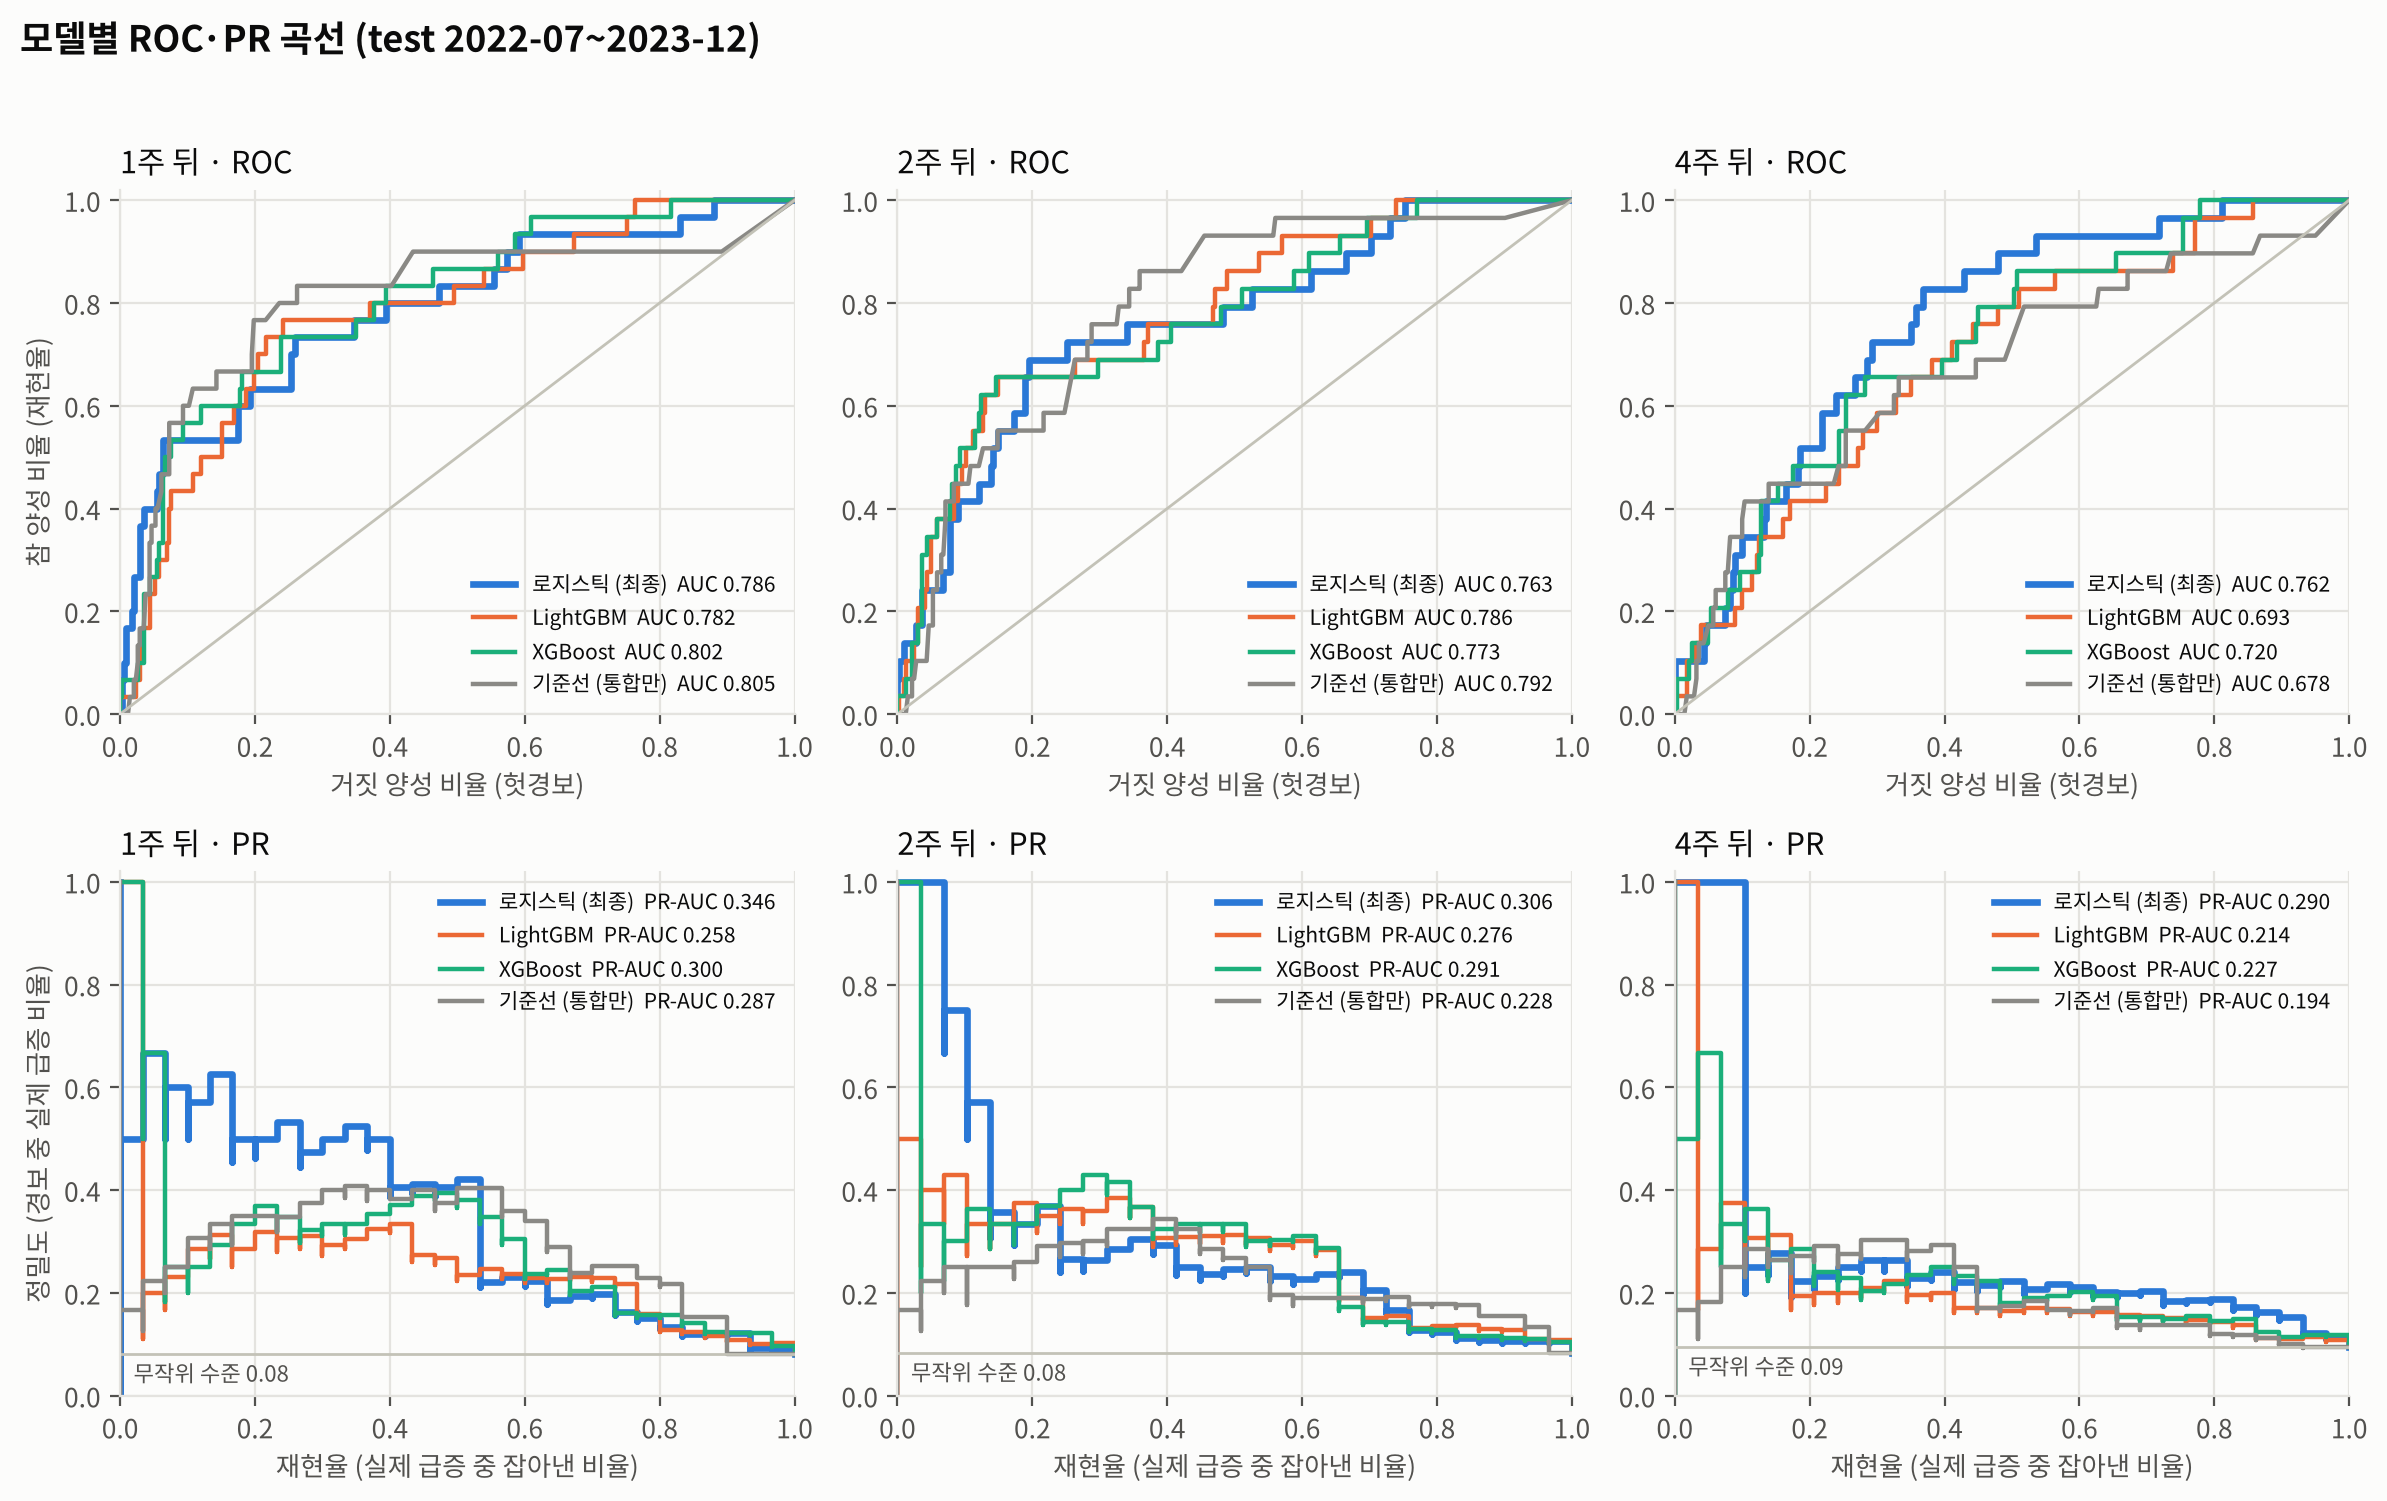

저장: 그림/모델비교_ROC_PR곡선.png


In [14]:
order = ["Logistic", "LightGBM", "XGBoost", "기준선"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7.6))
for j, k in enumerate(HORIZONS):
    ax_roc, ax_pr = axes[0, j], axes[1, j]
    for name in order:
        color, ls, label = STYLE[name]
        y, p = test_pred[(k, name)]
        fpr, tpr, _ = roc_curve(y, p)
        prec, rec, _ = precision_recall_curve(y, p)
        lw = 2.4 if name == "Logistic" else 1.6
        ax_roc.plot(fpr, tpr, color=color, ls=ls, lw=lw, label=f"{label}  AUC {roc_auc_score(y, p):.3f}")
        ax_pr.plot(rec, prec, color=color, ls=ls, lw=lw, label=f"{label}  PR-AUC {average_precision_score(y, p):.3f}",
                   drawstyle="steps-post")
    base = y.mean()
    ax_roc.plot([0, 1], [0, 1], color="#c3c2b7", lw=1)
    ax_pr.axhline(base, color="#c3c2b7", lw=1)
    ax_pr.text(0.02, base - 0.015, f"무작위 수준 {base:.2f}", ha="left", va="top", fontsize=8, color=INK2)
    ax_roc.set_title(f"{k}주 뒤 · ROC", loc="left", fontsize=11, color=INK)
    ax_pr.set_title(f"{k}주 뒤 · PR", loc="left", fontsize=11, color=INK)
    ax_roc.set_xlabel("거짓 양성 비율 (헛경보)")
    ax_pr.set_xlabel("재현율 (실제 급증 중 잡아낸 비율)")
    if j == 0:
        ax_roc.set_ylabel("참 양성 비율 (재현율)")
        ax_pr.set_ylabel("정밀도 (경보 중 실제 급증 비율)")
    for ax in (ax_roc, ax_pr):
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); style_ax(ax)
        ax.legend(loc="lower right" if ax is ax_roc else "upper right", fontsize=7.6, frameon=False)
fig.suptitle("모델별 ROC·PR 곡선 (test 2022-07~2023-12)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(f"{FIG}/모델비교_ROC_PR곡선.png", dpi=200)
plt.show()
print(f"저장: {FIG}/모델비교_ROC_PR곡선.png")